El **Forest CoverType dataset** es un conjunto de datos clásico para problemas de clasificación multiclase en aprendizaje automático. Contiene información sobre el tipo de cobertura forestal en cuatro áreas silvestres del Bosque Nacional Roosevelt, en el norte de Colorado.

Cada observación representa una parcela de bosque de 30x30 metros e incluye 54 características, como variables cuantitativas (por ejemplo, elevación, orientación, pendiente, distancia horizontal y vertical a la fuente hidrológica, índice de sombreado, distancia a las carreteras, etc.) y variables categóricas (área silvestre y tipo de suelo).

La **variable objetivo** de este conjunto de datos es Cover_Type, que clasifica cada parcela de bosque en uno de siete tipos:

1.  Spruce/Fir
2.  Lodgepole Pine
3.  Ponderosa Pine
4.  Cottonwood/Willow
5.  Aspen
6.  Douglas-fir
7.  Krummholz

El objetivo es predecir el tipo de cobertura forestal en función de las características ambientales dadas.



*   **581,012 registros**
*   **54 features**
*   **7 clases**







In [92]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Input

In [93]:
data = fetch_covtype()
data

{'data': array([[2.596e+03, 5.100e+01, 3.000e+00, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        [2.590e+03, 5.600e+01, 2.000e+00, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        [2.804e+03, 1.390e+02, 9.000e+00, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        ...,
        [2.386e+03, 1.590e+02, 1.700e+01, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        [2.384e+03, 1.700e+02, 1.500e+01, ..., 0.000e+00, 0.000e+00,
         0.000e+00],
        [2.383e+03, 1.650e+02, 1.300e+01, ..., 0.000e+00, 0.000e+00,
         0.000e+00]]),
 'target': array([5, 5, 2, ..., 3, 3, 3], dtype=int32),
 'frame': None,
 'target_names': ['Cover_Type'],
 'feature_names': ['Elevation',
  'Aspect',
  'Slope',
  'Horizontal_Distance_To_Hydrology',
  'Vertical_Distance_To_Hydrology',
  'Horizontal_Distance_To_Roadways',
  'Hillshade_9am',
  'Hillshade_Noon',
  'Hillshade_3pm',
  'Horizontal_Distance_To_Fire_Points',
  'Wilderness_Area_0',
  'Wilderness_Area_1',
  'Wilderness_Area_2',

In [94]:
print(data.target_names)
print(data.feature_names)
print(data.data.shape)
print(data.target.shape)

['Cover_Type']
['Elevation', 'Aspect', 'Slope', 'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology', 'Horizontal_Distance_To_Roadways', 'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm', 'Horizontal_Distance_To_Fire_Points', 'Wilderness_Area_0', 'Wilderness_Area_1', 'Wilderness_Area_2', 'Wilderness_Area_3', 'Soil_Type_0', 'Soil_Type_1', 'Soil_Type_2', 'Soil_Type_3', 'Soil_Type_4', 'Soil_Type_5', 'Soil_Type_6', 'Soil_Type_7', 'Soil_Type_8', 'Soil_Type_9', 'Soil_Type_10', 'Soil_Type_11', 'Soil_Type_12', 'Soil_Type_13', 'Soil_Type_14', 'Soil_Type_15', 'Soil_Type_16', 'Soil_Type_17', 'Soil_Type_18', 'Soil_Type_19', 'Soil_Type_20', 'Soil_Type_21', 'Soil_Type_22', 'Soil_Type_23', 'Soil_Type_24', 'Soil_Type_25', 'Soil_Type_26', 'Soil_Type_27', 'Soil_Type_28', 'Soil_Type_29', 'Soil_Type_30', 'Soil_Type_31', 'Soil_Type_32', 'Soil_Type_33', 'Soil_Type_34', 'Soil_Type_35', 'Soil_Type_36', 'Soil_Type_37', 'Soil_Type_38', 'Soil_Type_39']
(581012, 54)
(581012,)


In [95]:
X=data.data
y= data.target
print(X.shape)
print(y.shape)

(581012, 54)
(581012,)


In [96]:
print(np.unique(y))

[1 2 3 4 5 6 7]


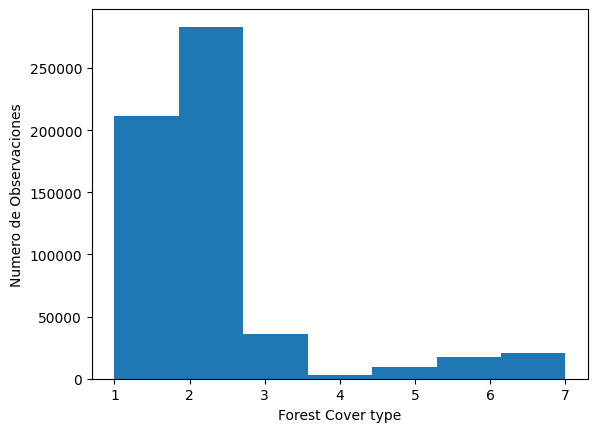

In [97]:
plt.hist(y, bins=7)
plt.xlabel("Forest Cover type")
plt.ylabel("Numero de Observaciones")
plt.show()
#Podemos concluir que tenemos un dataset desbalanceado

In [98]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape)
print(y_test.shape)
#Redes neuronales pueden trabajr con grandes cantidades de datos

(464809, 54)
(116203,)


In [99]:
scaler= StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [100]:
print(X_train[:, :15].min(axis=0))
print(X_train[:, :15].max(axis=0))

[ -3.92647635  -1.39157913  -1.88383182  -1.26818283  -3.64779621
  -1.50822261  -7.92628246 -11.29643041  -3.72504168  -1.49593745
  -0.90200878  -0.23266816  -0.87973359  -0.26093942  -0.0723893 ]
[ 3.20860659  1.82329031  6.93125276  5.30936385  9.52351425  3.05591475
  1.56447539  1.5521202   2.91253344  3.92276827  1.10863666  4.29796671
  1.13670776  3.83230717 13.81419655]


# **Crear la red Neuronal**

Dense.- Son capas densas totalmente conectadas.
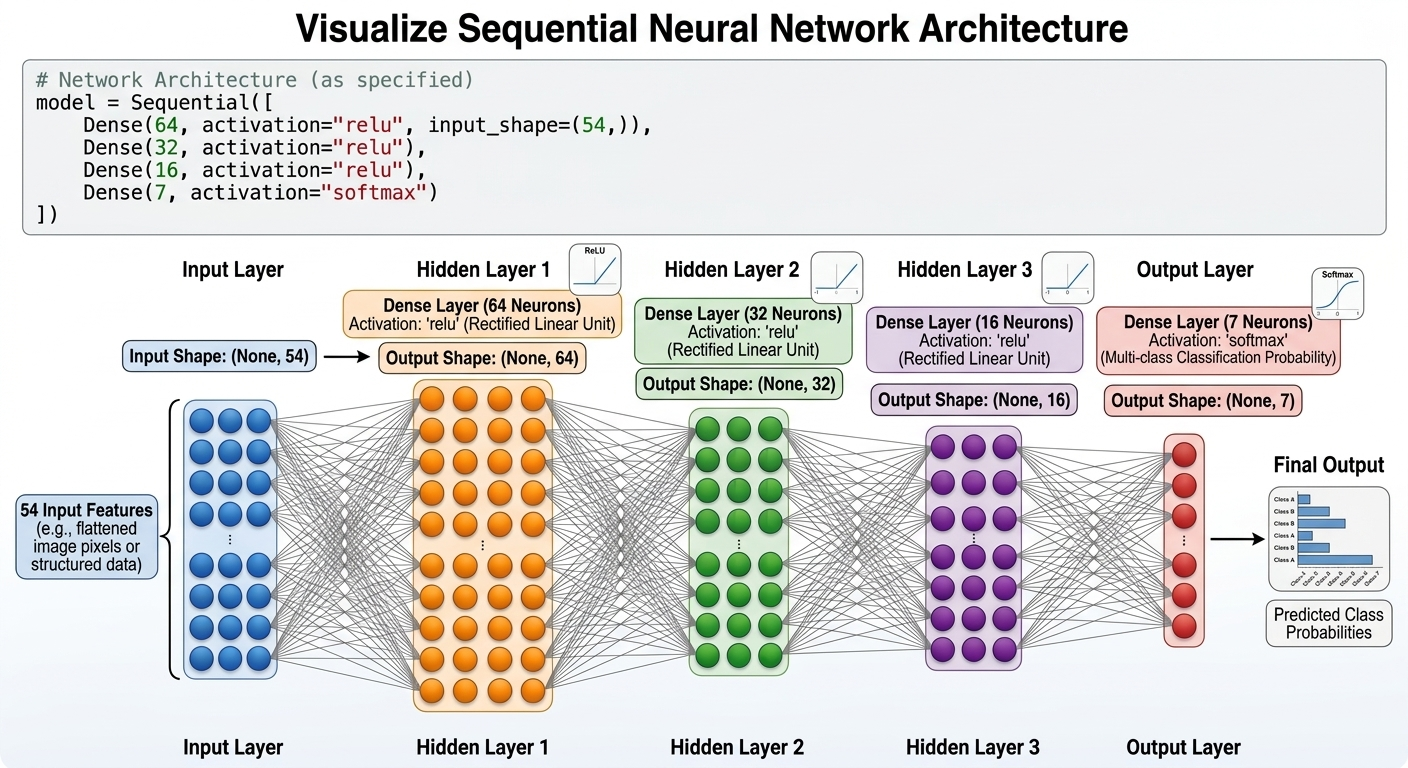

In [101]:
mimodelo = Sequential([
    Input(shape=(54,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(7, activation="softmax")
])

In [102]:
# Indicar al modelo como evaluar el rendimiento y como actualizar
# los parametros durante el entrenamiento
mimodelo.compile(
    optimizer="adam",  #adaptive moment estimation; gradiente descendiente. optimiza pesos
    loss= "sparse_categorical_crossentropy", #funcion de perdida multiclase. mide el error.
    metrics=["accuracy"] # acc= predicciones correctas/predicciones totales. mide predicciones correctas
)

In [104]:
#Entrenar
historia = mimodelo.fit(
    X_train,
    y_train-1,
    epochs=20,
    batch_size=512,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
818/818 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7092 - loss: 0.7100 - val_accuracy: 0.7537 - val_loss: 0.5766
Epoch 2/20
818/818 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7665 - loss: 0.5447 - val_accuracy: 0.7755 - val_loss: 0.5246
Epoch 3/20
818/818 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7835 - loss: 0.5050 - val_accuracy: 0.7884 - val_loss: 0.4944
Epoch 4/20
818/818 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7960 - loss: 0.4790 - val_accuracy: 0.7986 - val_loss: 0.4700
Epoch 5/20
818/818 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8051 - loss: 0.4603 - val_accuracy: 0.8081 - val_loss: 0.4517
Epoch 6/20
818/818 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8117 - loss: 0.4461 - val_accuracy: 0.8135 - val_loss: 0.4440
Epoch 7/20
818/818 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8182 - loss: 0.4339 - val_accuracy: 0.8124 - val_loss: 0.4413
Epoch 8/20
818/818 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8226 - loss: 0.4255 - val_accuracy: 0.

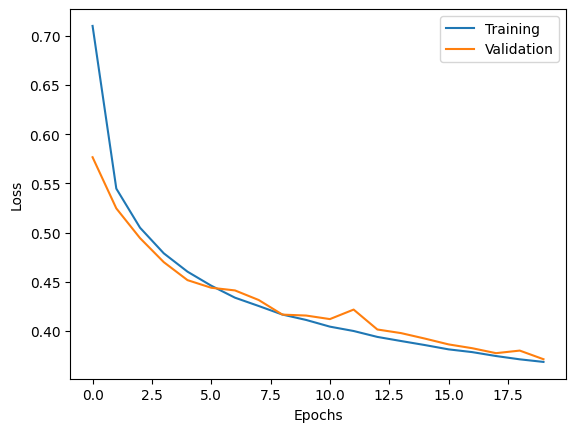

In [105]:
plt.plot(historia.history["loss"], label="Training")
#plt.plot(historia.history["accuracy"], label="Accuracy")
plt.plot(historia.history["val_loss"], label="Validation")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
mimodelo.score

In [106]:
#Prediccion
#cada fila es una observacion con la prob de pertenecer a cada clase (7)
y_prob = mimodelo.predict(X_test)
y_prob

3632/3632 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step


array([[5.45486450e-01, 4.54490125e-01, 3.26383343e-09, ...,
        4.33750483e-06, 1.16289582e-11, 1.90637547e-05],
       [1.11032432e-05, 5.12347445e-02, 8.51182580e-01, ...,
        9.24022198e-02, 5.16848126e-03, 6.22137065e-07],
       [5.86893272e-08, 6.08257234e-01, 1.80125296e-01, ...,
        1.31095633e-01, 8.05217251e-02, 2.13245741e-08],
       ...,
       [3.07505280e-01, 6.86011076e-01, 2.42197538e-13, ...,
        1.87356974e-08, 3.77373653e-12, 6.48357300e-03],
       [1.67978054e-03, 9.98319924e-01, 7.20717160e-13, ...,
        7.34743324e-08, 1.36226497e-09, 1.05630022e-07],
       [5.59951598e-03, 9.80977356e-01, 7.79053371e-05, ...,
        1.10623855e-02, 2.28286744e-03, 2.41149517e-10]], dtype=float32)

In [112]:
resultados= mimodelo.evaluate(X_test, y_test-1)
# (valor de la función de pérdida , precisión (accuracy)
resultados

3632/3632 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.8453 - loss: 0.3725


[0.37249085307121277, 0.8452966213226318]